# Q4. Variational Autoencoder (VAE) 

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm # For visualizing training progress
import numpy as np
import os

### > Include username in plots

In [2]:
username = "gracy.garg"
def add_username_to_plot(username="gracy.garg"):
    """
    Adds the username to the top-right corner of the current plot.
    """
    ax = plt.gca()
    # For 3D axes, use text2D to place text in axes (fractional) coordinates
    if getattr(ax, "name", "") == "3d" or ax.__class__.__name__ == "Axes3D":
        ax.text2D(0.95, 0.95, username, ha="right", va="top", transform=ax.transAxes,
                  fontsize=10, color="gray", alpha=0.7)
    else:
        plt.text(0.95, 0.95, username, ha="right", va="top",
                 transform=plt.gca().transAxes, fontsize=10, color="gray", alpha=0.7)

In [3]:
DATA_DIR = '../data/Q4'
OUTPUT_DIR='./output'
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)
CHECKPOINT_DIR = './checkpoints'
checkpoint_file = f'{CHECKPOINT_DIR}/vae_beta1.0_final_latent20.pt'
if not os.path.exists(CHECKPOINT_DIR):
    os.makedirs(CHECKPOINT_DIR)

In [4]:
LATENT_DIM = 64  # Starting dimension for latent space
HIDDEN_DIM = 400
INPUT_DIM = 784
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 50
BETA = 1.0 # Standard VAE setting
INPUT_CHANNELS = 1 
IMAGE_SIZE = 28

## 4.1 Introduction

## 4.2 Dataset Preparation [2 Marks]

In [5]:
def load_and_preprocess_data(batch_size):
    """
    Loads, preprocesses, and creates DataLoader instances for Fashion-MNIST.
    """
    print("Loading and Preprocessing Fashion-MNIST...")
    # 1. Normalization: Scale pixels to [0, 1]
    transform = transforms.ToTensor() 

    # 2. Load Data
    train_data = datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
    test_data = datasets.FashionMNIST('./data', train=False, download=True, transform=transform)

    # 3. Create DataLoaders
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)
    
    print(f"Data Loaders created (Batch Size: {batch_size}).")
    return train_loader, test_loader, train_data, test_data

## 4.3 Model Architecture [10 Marks]


### Implementation Snippet (VAE Class)

In [6]:
class VAE(nn.Module):
    """
    Convolutional Variational Autoencoder (C-VAE) for 28x28 images.
    Replaces MLPs with CNNs/Deconvs for spatial feature preservation.
    """
    def __init__(self, latent_dim=LATENT_DIM):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        
        # --- 1. ENCODER (CNN) ---
        self.encoder_conv = nn.Sequential(
            # Input: 1 x 28 x 28
            nn.Conv2d(INPUT_CHANNELS, 32, kernel_size=3, stride=2, padding=1), # Output: 32 x 14 x 14
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),             # Output: 64 x 7 x 7
            nn.ReLU()
        )
        
        # Calculate the size of the flattened layer
        # 64 channels * 7 * 7 = 3136 features
        self.flatten_size = 64 * 7 * 7
        
        # Final layers to calculate Mu and LogVar
        self.fc_mu = nn.Linear(self.flatten_size, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_size, latent_dim)

        # --- 2. DECODER (DECONV/CONV_TRANSPOSE) ---
        
        # Initial FC layer maps latent code back to the flattened CNN output size
        self.fc_decode = nn.Linear(latent_dim, self.flatten_size)
        
        self.decoder_deconv = nn.Sequential(
            # Reshape back to 64 x 7 x 7
            
            # Upscale 1: 64x7x7 -> 32x14x14
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            
            # Upscale 2: 32x14x14 -> 16x28x28
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            
            # Final Layer: 16x28x28 -> 1x28x28
            nn.Conv2d(16, INPUT_CHANNELS, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid() # Output in range [0, 1]
        )

    def reparameterize(self, mu, logvar):
        """Implements the Reparameterization Trick."""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std            
        return z

    def encode(self, x):
        # Input x shape: (N, 1, 28, 28)
        
        # 1. Pass through CNN layers
        h = self.encoder_conv(x)
        # h shape: (N, 64, 7, 7)
        
        # 2. Flatten for FC layers
        h = h.view(h.size(0), -1) 
        
        # 3. Output mu and logvar
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        # 1. Map latent code z to the required flattened size
        h = F.relu(self.fc_decode(z))
        
        # 2. Reshape to the starting feature map dimensions for deconvolution
        # h shape: (N, 3136) -> (N, 64, 7, 7)
        h = h.view(-1, 64, 7, 7) 
        
        # 3. Pass through deconvolutional layers
        x_recon = self.decoder_deconv(h)
        
        # Output x_recon shape: (N, 1, 28, 28)
        return x_recon

    def forward(self, x):
        # Ensure input is not flattened yet (x shape: N x 1 x 28 x 28)
        # Note: Input data loader should provide (N, 1, 28, 28) already, 
        # but we handle the reshaping if it comes flattened
        if x.dim() == 2:
            x = x.view(-1, INPUT_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
            
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z)
        
        # Flatten the output to match the original VAE loss function expected shape (N, 784)
        return x_recon.view(-1, INPUT_DIM), mu, logvar

def initialize_vae(latent_dim):
    """Initializes the VAE model."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = VAE(latent_dim).to(device)
    print(f"VAE initialized with Latent Dim: {latent_dim} on {device}")
    return model, device

### Influence of Latent Dimensions and Depth

The architectural hyperparameters directly influence both latent space structure and reconstruction quality:

* Small latent dimensions → meaningful, smooth manifold but poor detail. 
Moderate latent dimensions → best trade-off between smoothness and accuracy.  
Large latent dimensions → sharp reconstructions but broken generative manifold

* Deeper models → higher fidelity at the cost of latent coherence

Balanced architectures produce smooth transitions, diverse generations, and realistic reconstructions.

## 4.4 Loss Function [4 Marks]

### Implementation Snippet (Loss Function)

In [7]:

def vae_loss_function(x_recon, x, mu, logvar, beta=1.0):
    """
    Calculates the total VAE loss: Reconstruction Loss + beta * KL Divergence.
    """
    x = x.view(-1, INPUT_DIM)

    # 1. Reconstruction Loss (BCE)
    # Binary Cross-Entropy (BCE) measures pixel-wise similarity.
    # reduction='sum' ensures we sum over all pixels AND all samples in the batch.
    recon_loss = F.binary_cross_entropy(x_recon, x, reduction='sum')

    # 2. KL Divergence
    # D_KL(q(z|x) || p(z)) = -0.5 * sum(1 + log(σ²) - μ² - σ²)
    # This regularizes the latent space towards a standard normal prior N(0, I).
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    # Total Loss (ELBO minimization)
    total_loss = recon_loss + beta * kl_div
    return total_loss, recon_loss, kl_div

### Role of Loss Components

### 4.4 Loss Function — Role of Each Term
L=Eq(z∣x)​[logp(x∣z)]−DKL​(q(z∣x)∥p(z))

#### 1. Reconstruction Loss (BCE)

* Ensures the decoder can accurately reconstruct the input image.
* Forces the latent code to capture meaningful visual details.
* Higher weight → sharper, more faithful reconstructions.

#### 2. KL Divergence Term

* Regularizes the latent distribution to match the Gaussian prior ( \mathcal{N}(0, I) ).
* Ensures a smooth, continuous latent space where interpolation works.
* Higher weight → smoother manifold but blurrier reconstructions.

#### Joint Effect

* Reconstruction loss promotes fidelity.
* KL term promotes smoothness + generative consistency.
* A balanced VAE yields both good reconstructions and realistic samples.



## 4.5 Training Procedure 

### Implementation Snippet (Training Loop)

In [8]:
def save_model(model, optimizer, epoch, loss, filename):
    """
    Save model checkpoint with training state.
    """
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
        'latent_dim': model.latent_dim
    }
    torch.save(checkpoint, filename)
    print(f"✓ Model saved to {filename}")


def load_model(filename, latent_dim, device, hidden_dim=HIDDEN_DIM, input_dim=INPUT_DIM):
    """
    Load model checkpoint and restore training state.
    """
    model = VAE(input_dim, hidden_dim, latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    checkpoint = torch.load(filename, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch = checkpoint['epoch']
    loss = checkpoint['loss']
    
    print(f"✓ Model loaded from {filename} (Epoch: {epoch}, Loss: {loss:.4f})")
    return model, optimizer, epoch, loss

In [9]:
def train_model(model, train_loader, optimizer, device, epochs, beta, latent_viz_data=None, viz_frequency=None, save_checkpoint=True, checkpoint_dir='./checkpoints'):
    """
    Trains the VAE model and records loss components.
    """
    # Create checkpoint directory
    if save_checkpoint:
        os.makedirs(checkpoint_dir, exist_ok=True)
    
    model.train()
    history = {'total_loss': [], 'recon_loss': [], 'kl_div': []}
    latent_snapshots = []
    # best_loss = float('inf')
    # epochs_no_improve = 0
    # patience = 10

    for epoch in range(1, epochs + 1):
        running_total_loss = 0.0
        running_recon_loss = 0.0
        running_kl_div = 0.0
        
        # Use tqdm for a neat progress bar
        pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} (β={beta})")
        
        for batch_idx, (data, _) in enumerate(pbar):
            data = data.to(device)
            optimizer.zero_grad()
            
            x_recon, mu, logvar = model(data)
            total_loss, recon_loss, kl_div = vae_loss_function(x_recon, data, mu, logvar, beta)
            
            total_loss.backward()
            optimizer.step()
            
            # Record losses normalized by batch size for plotting consistency
            batch_loss = total_loss.item() / data.size(0)
            running_total_loss += total_loss.item() 
            running_recon_loss += recon_loss.item() 
            running_kl_div += kl_div.item()

            # Update progress bar description
            pbar.set_postfix({'Total Loss': f'{batch_loss:.4f}', 
                              'Recon Loss': f'{recon_loss.item()/data.size(0):.4f}'})
            
            if latent_viz_data and viz_frequency and (batch_idx % viz_frequency == 0):
                model.eval() # Switch to evaluation mode for snapshot
                with torch.no_grad():
                    viz_images, _ = next(iter(latent_viz_data))
                    viz_images = viz_images.to(device)
                    _, mu_viz, _ = model(viz_images)
                    latent_snapshots.append(mu_viz.cpu().numpy())
                model.train() # Switch back to training mode

        # Calculate average epoch loss
        num_batches = len(train_loader)
        avg_total_loss = running_total_loss / num_batches
        avg_recon_loss = running_recon_loss / num_batches
        avg_kl_div = running_kl_div / num_batches
        
        # Store history
        history['total_loss'].append(avg_total_loss)
        history['recon_loss'].append(avg_recon_loss)
        history['kl_div'].append(avg_kl_div)

        if save_checkpoint and (epoch % 10 == 0 or epoch == epochs):
            checkpoint_path = os.path.join(
                checkpoint_dir, 
                f'vae_beta{beta}_epoch{epoch}_latent{model.latent_dim}.pt'
            )
            save_model(model, optimizer, epoch, avg_total_loss, checkpoint_path)

        # if avg_total_loss < best_loss:
        #     best_loss = avg_total_loss
        #     epochs_no_improve = 0
        # else:
        #     epochs_no_improve += 1
        
        # if epochs_no_improve >= patience:
        #     print(f"\nEarly stopping triggered at epoch {epoch} due to no improvement for {patience} epochs.")
        #     break

    print(f"\nTraining complete for β={beta}. Final Avg Loss: {avg_total_loss:.4f}")
    if save_checkpoint:
        final_path = os.path.join(
            checkpoint_dir,
            f'vae_beta{beta}_final_latent{model.latent_dim}.pt'
        )
        save_model(model, optimizer, epochs, avg_total_loss, final_path)
    
    return history, latent_snapshots

### Loss Component Plotting

In [10]:
def plot_loss_components(history, beta):
    """
    Plots the total loss and its components over epochs.
    """
    plt.figure(figsize=(10, 5))
    epochs = range(1, len(history['total_loss']) + 1)
    
    plt.plot(epochs, history['total_loss'], label='Total Loss', color='darkred')
    plt.plot(epochs, history['recon_loss'], label='Reconstruction Loss', color='blue')
    plt.plot(epochs, history['kl_div'], label=f'KL Divergence (scaled by β={beta})', color='green')
    
    plt.title(f'VAE Training Loss Components Over Epochs (β={beta})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    add_username_to_plot(username)
    plt.savefig(os.path.join(OUTPUT_DIR, f'loss_components_beta_{beta}.png'))
    plt.show()

## 4.6 Experimental Analysis ($\beta$-VAE) [9 Marks]

### Implementation 

In [11]:
import ffmpeg
from torch.utils.data import Subset
from matplotlib.animation import FuncAnimation
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
import matplotlib.cm as cm  
import math 

In [12]:
def _tensor_to_image_np(tensor):
    """
    Convert torch tensor image to HxW or HxWx3 numpy in [0,1].
    Accepts (C,H,W) or (1,H,W) or (H,W) or (H,W,1) or (C,H,W) batched.
    Returns float32 in [0,1].
    """
    import torch
    if isinstance(tensor, torch.Tensor):
        arr = tensor.detach().cpu().numpy()
    else:
        arr = np.array(tensor)
    # If batched
    if arr.ndim == 4:  # (N,C,H,W)
        # return list of images
        imgs = []
        for i in range(arr.shape[0]):
            imgs.append(_tensor_to_image_np(arr[i]))
        return imgs
    # Now single image
    if arr.ndim == 3 and arr.shape[0] in (1,3):  # (C,H,W)
        arr = np.transpose(arr, (1, 2, 0))  # H W C
    if arr.ndim == 2:
        # H W -> H W (grayscale)
        arr = arr
    # If last channel is 1, squeeze
    if arr.ndim == 3 and arr.shape[2] == 1:
        arr = arr[..., 0]
    # normalize to [0,1] if dtype is uint8 or outside range
    arr = arr.astype(np.float32)
    mn, mx = arr.min(), arr.max()
    if mx > 1.1:  # probably 0-255
        arr = arr / 255.0
    elif mx <= 1.1 and mn < 0.0:
        # shift/clamp
        arr = (arr - mn) / (mx - mn + 1e-9)
    return arr

def save_latent_evolution_animation(
    latent_snapshots,
    labels_list,
    images_np_list,
    epochs,
    beta,
    filename,
    figsize=(8,8),
    thumbnail_zoom=0.18,
    max_thumbnails=150,
    cmap='tab10',
    fps=6
):
    """
    Creates an animation of latent space evolution during training.
    """
    if not latent_snapshots:
        print("No latent snapshots provided. Skipping.")
        return

    # Ensure arrays
    labels_arr = np.asarray(labels_list)
    imgs_list = images_np_list if isinstance(images_np_list, list) else list(images_np_list)

    total_frames = len(latent_snapshots)
    
    # All snapshots should have the same shape
    n_points = latent_snapshots[0].shape[0]

    # Precompute global percentiles for tight axes
    all_x = np.concatenate([s[:, 0] for s in latent_snapshots])
    all_y = np.concatenate([s[:, 1] for s in latent_snapshots])
    p1, p99 = np.percentile(all_x, [1, 99])
    q1, q99 = np.percentile(all_y, [1, 99])
    
    x_span = max(1e-3, p99 - p1)
    y_span = max(1e-3, q99 - q1)
    x_margin = max(0.5, 0.05 * x_span)
    y_margin = max(0.5, 0.05 * y_span)

    # colors for labels
    unique_labels = np.unique(labels_arr)
    cmap_obj = plt.get_cmap(cmap, max(10, len(unique_labels)))
    label_to_color = {int(lbl): cmap_obj(i) for i, lbl in enumerate(unique_labels)}

    fig, ax = plt.subplots(figsize=figsize)

    # legend proxies
    legend_handles = []
    legend_labels = []
    for lbl in unique_labels:
        color = label_to_color[int(lbl)]
        legend_handles.append(Line2D([0], [0], marker='o', color='w', 
                                    markerfacecolor=color, markersize=8))
        legend_labels.append(f'Class {int(lbl)}')

    def _ensure_rgb_float(im):
        arr = np.array(im, dtype=np.float32)
        if arr.ndim == 3 and arr.shape[0] in (1,3):
            arr = np.transpose(arr, (1,2,0))
        if arr.ndim == 2:
            arr = np.stack([arr, arr, arr], axis=-1)
        if arr.ndim == 3 and arr.shape[2] == 1:
            arr = np.concatenate([arr]*3, axis=2)
        mn, mx = arr.min(), arr.max()
        if mx > 1.1:
            arr = arr / 255.0
        elif mx <= 1.1 and mn < 0.0:
            arr = (arr - mn) / (mx - mn + 1e-9)
        arr = np.clip(arr, 0.0, 1.0)
        return arr

    def update(frame):
        ax.clear()
        ax.set_xlim(p1 - x_margin, p99 + x_margin)
        ax.set_ylim(q1 - y_margin, q99 + y_margin)
        ax.set_xlabel('Latent dim 1')
        ax.set_ylabel('Latent dim 2')
        ax.grid(True, linestyle='--', alpha=0.4)

        mus = latent_snapshots[frame]  # Shape: (n_points, 2)
        frame_labels = labels_arr  # Use ALL labels (same for every frame)
        imgs = imgs_list  # Use ALL images (same for every frame)

        colors = [label_to_color[int(l)] for l in frame_labels]
        ax.scatter(mus[:,0], mus[:,1], c=colors, s=16, alpha=0.9, linewidths=0)

        if n_points == 0:
            return []
        
        step = max(1, math.ceil(n_points / max_thumbnails))
        draw_indices = list(range(0, n_points, step))

        jitter_scale_x = 0.002 * x_span if x_span > 0 else 0.01
        jitter_scale_y = 0.002 * y_span if y_span > 0 else 0.01

        for idx in draw_indices:
            try:
                im_np = _ensure_rgb_float(imgs[idx])
            except Exception:
                im_np = np.ones((28,28,3), dtype=np.float32) * 0.5

            oi = OffsetImage(im_np, zoom=thumbnail_zoom, resample=True)
            x0 = float(mus[idx, 0] + np.random.normal(scale=jitter_scale_x))
            y0 = float(mus[idx, 1] + np.random.normal(scale=jitter_scale_y))

            ab = AnnotationBbox(oi, (x0, y0), frameon=True, pad=0.02,
                               bboxprops=dict(edgecolor='k', linewidth=0.2, 
                                            facecolor='white', alpha=0.95))
            ab.set_zorder(100)
            ab.set_clip_on(False)
            ax.add_artist(ab)

        ax.legend(legend_handles, legend_labels, loc='upper right', 
                 title='Classes', fontsize='small')

        snapshots_per_epoch = max(1, total_frames // epochs)
        epoch_num = (frame // snapshots_per_epoch) + 1
        ax.set_title(f"Latent evolution β={beta} | Epoch ~{epoch_num}/{epochs} | frame {frame+1}/{total_frames}")

        return []

    anim = FuncAnimation(fig, update, frames=total_frames, interval=250, 
                        blit=False, repeat=False)

    # IMPROVED SAVING LOGIC
    if not filename.endswith('.gif'):
        filename = filename.rsplit('.', 1)[0] + '.gif'
    
    saved = False
    
    # Try ffmpeg
    try:
        anim.save(filename, writer='ffmpeg', fps=fps, dpi=80)
        print(f"✓ Saved animation to {filename}")
        saved = True
    except Exception as e:
        print(f"⚠ ffmpeg failed: {str(e)[:80]}")
    
    # Try pillow
    if not saved:
        try:
            anim.save(filename, writer='pillow', fps=fps)
            print(f"✓ Saved animation (Pillow) to {filename}")
            saved = True
        except Exception as e:
            print(f"⚠ Pillow failed: {str(e)[:80]}")
    
    # Save frames as fallback
    if not saved:
        try:
            frame_dir = filename.rsplit('.', 1)[0] + '_frames'
            os.makedirs(frame_dir, exist_ok=True)
            print(f"⚠ Saving frames to {frame_dir}/")
            
            for frame_idx in range(min(total_frames, 100)):
                update(frame_idx)
                plt.savefig(f'{frame_dir}/frame_{frame_idx:03d}.png', dpi=80)
            
            print("✓ Saved frames. Create GIF:")
            print(f"   ffmpeg -framerate {fps} -i {frame_dir}/frame_%03d.png {filename}")
        except Exception as e:
            print(f"✗ All strategies failed: {e}")
    
    plt.close(fig)

In [13]:
def run_beta_experiments(train_loader, beta_value, train_data, epochs=10):
    """
    Runs VAE training for different beta values and generates animation for each 
    using a single training pass.
    """
    beta_values = [beta_value]
    all_histories = {}
    
    LATENT_DIM_VIZ = 2  # ← Use 2D latent space for visualization
    CLASSES_TO_TRACK = [0, 1, 2] # 0: T-shirt/top, 1: Trouser, 2: Pullover
    
    print("--- Starting Efficient Beta-VAE Experiments (Latent Dim=2) ---")
    
    # --- Setup Visualization Data and Loader ---
    subset_indices = []
    for class_id in CLASSES_TO_TRACK:
        indices = [i for i, label in enumerate(train_data.targets) if label == class_id]
        subset_indices.extend(indices[:500]) # Limit points for visualization
    
    subset_data = Subset(train_data, subset_indices)
    subset_loader = DataLoader(subset_data, batch_size=len(subset_data), shuffle=False)
    
    # Get the static labels for the animation legend
    labels_list = np.array([train_data.targets[i].item() for i in subset_indices])
    images_np_list = []
    for idx in subset_indices:
        img, _ = train_data[idx]
        images_np_list.append(img.numpy())  # Convert tensor to numpy
    
    # Frequency to capture snapshots (e.g., capture 5 times per epoch)
    SNAPSHOT_FREQUENCY = len(train_loader) // 5 
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   
    
    for beta in beta_values:
        print(f"\n[EXPERIMENT] Training VAE with β = {beta}")
        print(f"Note: Using LATENT_DIM={LATENT_DIM_VIZ} for visualization purposes")
        
        # Use beta and latent-dim specific checkpoint
        checkpoint_file_beta = f'{CHECKPOINT_DIR}/vae_beta{beta}_final_latent{LATENT_DIM_VIZ}.pt'
        
        if os.path.exists(checkpoint_file_beta):
            print("Loading pre-trained model...")
            model, optimizer, last_epoch, last_loss = load_model(
                checkpoint_file_beta, 
                LATENT_DIM_VIZ,  # ← Use 2D latent dimension
                device
            )
            print(f"✓ Loaded model trained for {last_epoch} epochs")
            
            # Initialize empty structures (can't recover from checkpoint)
            history = {'total_loss': [], 'recon_loss': [], 'kl_div': []}
            latent_snapshots = []
            
            print("⚠ Warning: Loaded pre-trained model. To generate animations, retrain or delete checkpoint:")
            print(f"   rm {checkpoint_file_beta}")
        else:
            print("No checkpoint found. Training from scratch...")
            model, device = initialize_vae(LATENT_DIM_VIZ)  # ← Use 2D latent dimension
            optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        
            # 1. Train model and capture snapshots simultaneously
            history, latent_snapshots = train_model(
                model, 
                train_loader, 
                optimizer, 
                device, 
                epochs, 
                beta, 
                latent_viz_data=subset_loader,
                viz_frequency=SNAPSHOT_FREQUENCY,
                save_checkpoint=True,
                checkpoint_dir=CHECKPOINT_DIR   
            )
        
        all_histories[beta] = history
        
        # Only plot if we have history
        if history['total_loss']:
            plot_loss_components(history, beta)
        
        print("\nSnapshot check:")
        print(f"  Number of snapshots: {len(latent_snapshots)}")
        if latent_snapshots:
            print(f"  First snapshot shape: {latent_snapshots[0].shape}")
            print(f"  Labels shape: {labels_list.shape}")
            print(f"  Images count: {len(images_np_list)}")
            
            # Verify latent dimension is 2D before animation
            if latent_snapshots[0].shape[1] == 2:
                # 2. Generate animation from captured snapshots
                save_latent_evolution_animation(
                    latent_snapshots, 
                    labels_list, 
                    images_np_list,
                    epochs, 
                    beta, 
                    f'{OUTPUT_DIR}/latent_evolution_beta_{beta}.gif'
                )
            else:
                print(f"⚠ Error: Expected 2D latent space but got {latent_snapshots[0].shape[1]}D")
                print("   Animation requires 2D latent space for visualization.")
        else:
            print("⚠ No latent snapshots captured. Skipping animation.")
        
    print("--- Efficient Beta-VAE Experiments Complete ---")
    return all_histories

### Effect of β on VAE Behaviour

Increasing β strengthens the KL penalty, forcing better disentanglement but reducing reconstruction fidelity.

#### How β Affects the Model

#### 1. Image Sharpness & Reconstruction Quality

* β = 0.1 → KL term weak → model prioritizes reconstruction
  → Sharpest and most detailed reconstructions
* β = 0.5 → Balanced trade-off → slightly blurrier but still good
* β = 1.0 → Strong KL pressure → reconstructions become smoother/blurry

#### 2. Latent Space Smoothness

* Higher β pushes points closer to a Gaussian prior.
* Latent clusters compress and become better organized.
* Interpolations become smoother and more meaningful.

#### 3. Cluster Separation (Latent Space)

* β = 0.1 → Sharp reconstructions but overlapping clusters.
* β = 0.5 → Clearer separation emerges.
* β = 1.0 → Strongest clustering; classes form distinct regions.

#### 4. Generative Diversity

* Low β → Can overfit; samples resemble training images → low diversity
* Moderate β → Better mix of structure + variability
* High β → High diversity but sometimes over-regularized, losing detail


### Summary of Findings Table (Quantitative & Qualitative)

| β Value | Reconstruction Loss ↓ | KL Divergence ↑ | Image Quality | Diversity | Latent Clustering | Overall Comment               |
| ----------- | ------------------------- | ------------------- | ----------------- | ------------- | --------------------- | --------------------------------- |
| 0.1     | Lowest (best recon)   | Very Low            | Sharp, detailed   | Low–Medium    | Weak separation       | Prior ignored; recon dominates    |
| 0.5     | Moderate                  | Moderate            | Good balance      | High          | Clear class clusters  | Best trade-off (β-VAE sweet spot) |
| 1.0     | Highest (blurriest recon) | High                | Smooth / blurry   | Highest       | Strongest clustering  | Most disentangled but least sharp |



## 4.7 Evaluation and Visualization [3 Marks]

### Display Reconstructions

In [14]:
def display_reconstructions(model, test_loader, device, num_images=8):
    """Displays original and reconstructed test images side-by-side with cleaner labels."""
    model.eval()
    data, labels = next(iter(test_loader))
    data = data[:num_images].to(device)
    labels = labels[:num_images]
    
    # Fashion-MNIST class names
    class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                   'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
    
    with torch.no_grad():
        x_recon, mu, logvar = model(data)
    
    # Increase figure height for better spacing
    fig, axes = plt.subplots(2, num_images, figsize=(num_images * 1.8, 4.5))
    
    # Detach and reshape tensors for plotting
    original = data.cpu().view(-1, 28, 28)
    reconstructed = x_recon.cpu().view(-1, 28, 28)
    
    # Calculate reconstruction error for each image
    mse_errors = F.mse_loss(x_recon, data.view(-1, 784), reduction='none').mean(dim=1)
    
    for i in range(num_images):
        # Original Image
        axes[0, i].imshow(original[i], cmap='gray')
        axes[0, i].axis('off')
        
        # Add class name and image number as title
        class_name = class_names[labels[i].item()]
        axes[0, i].set_title(f"{class_name}", fontsize=9, pad=8, weight='bold')
        
        # Reconstructed Image
        axes[1, i].imshow(reconstructed[i], cmap='gray')
        axes[1, i].axis('off')
        
        # Add MSE error below reconstruction
        mse = mse_errors[i].item()
        axes[1, i].text(0.5, -0.15, f"MSE: {mse:.4f}", 
                       transform=axes[1, i].transAxes,
                       ha='center', fontsize=8, color='darkred')

    # Row labels with colored background boxes
    axes[0, 0].text(-0.3, 0.5, 'Original', 
                    transform=axes[0, 0].transAxes,
                    fontsize=12, weight='bold',
                    ha='right', va='center')
    
    axes[1, 0].text(-0.3, 0.5, 'Reconstructed', 
                    transform=axes[1, 0].transAxes,
                    fontsize=12, weight='bold',
                    ha='right', va='center')

    fig.suptitle("Original vs. Reconstructed Test Images", fontsize=16, weight='bold', y=0.98)
    add_username_to_plot(username)
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.savefig(os.path.join(OUTPUT_DIR, 'reconstructions.png'), bbox_inches='tight', dpi=150)
    plt.show()

### Generate New Samples

In [26]:
def generate_new_samples(model, device, num_samples=100, plot=True):
    """Generates new images by sampling from the N(0, I) prior."""
    model.eval()
    
    latent_dim = model.fc_mu.out_features 
    
    # 1. Sample from the standard normal prior N(0, I)
    z_samples = torch.randn(num_samples, latent_dim).to(device)
    
    with torch.no_grad():
        # 2. Decode the latent vectors
        generated_images = model.decode(z_samples)
    
    # 3. Reshape for return (N, 28, 28)
    generated_images_reshaped = generated_images.cpu().view(-1, 28, 28)
    
    # 4. Plot if requested
    if plot:
        num_plot = min(100, num_samples)  # Plot maximum 100 samples
        fig, axes = plt.subplots(10, 10, figsize=(15, 15))
        
        for i in range(num_plot):
            r = i // 10
            c = i % 10
            axes[r, c].imshow(generated_images_reshaped[i], cmap='gray')
            axes[r, c].axis('off')
            
            # Add sample number label (optional - can be removed if too cluttered)
            # axes[r, c].text(0.5, -0.05, f"{i+1}", 
            #                transform=axes[r, c].transAxes,
            #                ha='center', fontsize=7, 
            #                weight='bold', color='darkblue')
        
        # Add informative title
        fig.suptitle(f"Generated Samples from N(0, I) Prior\n(Latent Dim={latent_dim}, Total Samples={num_samples})", 
                    fontsize=16, weight='bold', y=0.995)
        
        # Add explanation text at bottom
        fig.text(0.5, 0.005, 
                "Each sample is decoded from a randomly sampled latent vector z ~ N(0, I)",
                ha='center', fontsize=11, style='italic', color='gray')
        
        add_username_to_plot(username)
        plt.tight_layout(rect=[0, 0.015, 1, 0.99])
        plt.savefig(os.path.join(OUTPUT_DIR, 'generated_samples.png'), bbox_inches='tight', dpi=150)
        plt.show()
    
    # Return as (N, 28, 28) tensor for FID calculation
    return generated_images_reshaped

### Evaluation Metric: Fréchet Inception Distance (FID) 


In [16]:
from scipy import linalg    
from torchvision.models import inception_v3     
def calculate_fid_from_arrays(real_images, gen_images, device='cuda', batch_size=32, eps=1e-6, min_samples=100):
    """
    Calculate FID between real and generated images.
    Args:
        real_images: numpy array or torch tensor (N, H, W) or (N, H, W, C) in [0,1]
        gen_images: numpy array or torch tensor (N, H, W) or (N, H, W, C) in [0,1]
        device: 'cuda' or 'cpu'
        batch_size: batch size for processing
        eps: epsilon for numerical stability
        min_samples: minimum recommended sample size (just for warning)
    Returns:
        FID score (float)
    """
    # Check sample sizes
    if len(real_images) < min_samples or len(gen_images) < min_samples:
        print(f"WARNING: FID calculation is less reliable with fewer than {min_samples} samples.")  
    
    # Convert to torch tensors if needed
    if isinstance(real_images, np.ndarray):
        real_images = torch.from_numpy(real_images).float()
    if isinstance(gen_images, np.ndarray):
        gen_images = torch.from_numpy(gen_images).float()
    
    # Normalize images to expected shape
    real_images = _prepare_images(real_images)
    gen_images = _prepare_images(gen_images)
    
    # Load InceptionV3 model
    model = _load_inception_model(device)
    
    # Extract features
    real_features = _extract_features(model, real_images, device, batch_size)
    gen_features = _extract_features(model, gen_images, device, batch_size)
    
    # Calculate statistics
    mu_real = np.mean(real_features, axis=0)
    sigma_real = np.cov(real_features, rowvar=False)
    
    mu_gen = np.mean(gen_features, axis=0)
    sigma_gen = np.cov(gen_features, rowvar=False)
    
    # Calculate FID
    fid = _calculate_frechet_distance(mu_real, sigma_real, mu_gen, sigma_gen, eps)
    
    return fid


def _prepare_images(images):
    """Prepare images: add channel dimension if needed and ensure (N, C, H, W) format."""
    # Add channel dimension if grayscale
    if images.ndim == 3:
        images = images.unsqueeze(1)  # (N, H, W) -> (N, 1, H, W)
    
    # Convert (N, H, W, C) to (N, C, H, W)
    if images.ndim == 4 and images.shape[-1] in [1, 3]:
        images = images.permute(0, 3, 1, 2)
    
    # Convert grayscale to RGB if needed
    if images.shape[1] == 1:
        images = images.repeat(1, 3, 1, 1)
    
    # Ensure values are in [0, 1]
    if images.max() > 1.0:
        images = images / 255.0
    
    return images


def _load_inception_model(device):
    """Load pretrained InceptionV3 model for feature extraction."""
    model = inception_v3(pretrained=True, transform_input=False)
    model.fc = nn.Identity()  # Remove final classification layer
    model = model.to(device)
    model.eval()
    return model


def _extract_features(model, images, device, batch_size):
    """Extract InceptionV3 features from images."""
    features = []
    
    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = images[i:i+batch_size].to(device)
            
            # Resize to 299x299 for InceptionV3
            if batch.shape[2:] != (299, 299):
                batch = nn.functional.interpolate(
                    batch, size=(299, 299), mode='bilinear', align_corners=False
                )
            
            # Normalize to [-1, 1] as expected by InceptionV3
            batch = batch * 2 - 1
            
            # Extract features
            feat = model(batch)
            features.append(feat.cpu().numpy())
    
    features = np.concatenate(features, axis=0)
    return features


def _calculate_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    """
    Calculate Frechet distance between two multivariate Gaussians.
    
    FID = ||mu1 - mu2||^2 + Tr(sigma1 + sigma2 - 2*sqrt(sigma1*sigma2))
    """
    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)
    
    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)
    
    # Calculate mean difference
    diff = mu1 - mu2
    
    # Calculate covariance square root
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    
    # Handle numerical errors
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
    
    # Numerical error might give slight imaginary component
    if np.iscomplexobj(covmean):
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            m = np.max(np.abs(covmean.imag))
            raise ValueError(f"Imaginary component {m} too large")
        covmean = covmean.real
    
    tr_covmean = np.trace(covmean)
    
    # Calculate FID
    fid = diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * tr_covmean
    
    return float(fid)

### Interpretation of Generated Samples


### (Latent Dim = 20, Fashion-MNIST)

### 1. Quality, Diversity, and Realism of Generated Samples

Figure (Samples from N(0, I) prior) shows 100 images decoded from randomly sampled latent vectors.

#### Quality

* The generated images are *recognizable* as Fashion-MNIST categories (shirts, trousers, coats, boots).
* Many samples retain the global silhouette, but show:

  * blurry edges
  * weaker fine-grained texture
  * average-like shapes

This is expected because VAEs maximize a reconstruction + KL loss, which encourages the decoder to output smooth, average-looking samples rather than crisp details.

#### Diversity

* The model generates all major item classes, which shows strong latent coverage.
* However, the images still look similar within each class → indicating that latent variance is partially collapsed.

#### Realism

* Shapes are plausible; most images look like actual Fashion-MNIST clothing.
* Realism is limited by:

  * VAE's pixel-space Gaussian likelihood → inherently produces *blur*
  * KL regularization pulling latent codes toward zero


## 4.8 Effect of Frozen Latent Parameters [5 Marks]

### Implementation Snippet (Generating Frozen Samples)

In [17]:
def generate_frozen_samples(model, device, mu_fixed, sigma_list, latent_dim, num_samples=8):
    """
    Generates samples by decoding manually constructed latent vectors z.
    The mean (μ) is fixed, and standard deviation (σ) is varied.
    
    Each ROW shows samples for a different σ value.
    Each COLUMN shows a different random sample (different ϵ).
    """
    model.eval()
    
    fig, axes = plt.subplots(len(sigma_list), num_samples, figsize=(num_samples * 1.5, len(sigma_list) * 1.8))
    
    print(f"\n[FROZEN LATENT EXPERIMENT] Generating samples with μ fixed to {mu_fixed}...")
    print("=" * 60)
    
    for row_idx, sigma_fixed in enumerate(sigma_list):
        # 1. Define fixed μ and σ tensors
        mu = torch.full((num_samples, latent_dim), mu_fixed, dtype=torch.float32).to(device)
        std = torch.full((num_samples, latent_dim), sigma_fixed, dtype=torch.float32).to(device)
        
        # 2. Sample ϵ and construct the latent vector z
        eps = torch.randn_like(std).to(device)
        z_frozen = mu + eps * std  # z = μ_fixed + ϵ * σ_fixed
        
        with torch.no_grad():
            generated_images = model.decode(z_frozen)
            
        generated_images = generated_images.cpu().view(-1, 28, 28)
        
        # Calculate diversity metric for this row
        diversity = torch.std(torch.stack([generated_images[i] for i in range(num_samples)])).item()
        print(f"Row {row_idx + 1}: σ={sigma_fixed:4.1f} | Sample diversity (std): {diversity:.4f}")
        
        for col_idx in range(num_samples):
            ax = axes[row_idx, col_idx]
            ax.imshow(generated_images[col_idx], cmap='gray')
            ax.axis('off')
            
            # Add column labels on the first row
            if row_idx == 0:
                ax.set_title(f"Sample {col_idx+1}", fontsize=9, pad=5)
            
            # Add row labels on the first column with better positioning
            if col_idx == 0:
                ax.text(-0.5, 0.5, f"σ = {sigma_fixed}", 
                       transform=ax.transAxes,
                       fontsize=12, 
                       weight='bold',
                       ha='right', 
                       va='center',
                       )

    print("=" * 60)
    print(f"✓ Higher σ → More diverse samples (larger exploration in latent space)")
    print(f"✓ Lower σ → More similar samples (smaller exploration around μ={mu_fixed})")
    
    # Add overall title with explanation
    title = f"Effect of Varying σ on Generated Samples\n(Fixed μ={mu_fixed}, Latent Dim={latent_dim})"
    fig.suptitle(title, fontsize=14, weight='bold', y=0.98)
    
    # Add text explanation at bottom
    fig.text(0.5, 0.02, 
             "Samples for different σ values",
             ha='center', fontsize=10, style='italic', color='gray')
    
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    add_username_to_plot(username)
    
    plt.savefig(os.path.join(OUTPUT_DIR, 'frozen_latent_samples.png'), bbox_inches='tight', dpi=150)
    plt.show()

### Evaluation and Discussion

In [18]:
train_loader, test_loader, train_data, test_data = load_and_preprocess_data(BATCH_SIZE)
vae_model, device = initialize_vae(LATENT_DIM)
optimizer = torch.optim.Adam(vae_model.parameters(), lr=LEARNING_RATE)


Loading and Preprocessing Fashion-MNIST...
Data Loaders created (Batch Size: 128).
VAE initialized with Latent Dim: 64 on cuda


In [19]:
# 4.5 Train Standard VAE (β=1.0)
print("\n--- Training Standard VAE (β=2.0) ---")

if os.path.exists(checkpoint_file):
    print("Loading pre-trained model...")
    vae_model, optimizer, last_epoch, last_loss = load_model(
        checkpoint_file, 
        LATENT_DIM, 
        device
    )
    print(f"Resuming from epoch {last_epoch}")
else:
    print("No checkpoint found. Training from scratch...")
    vae_model, device = initialize_vae(LATENT_DIM)
    optimizer = torch.optim.Adam(vae_model.parameters(), lr=LEARNING_RATE)
    standard_history, _ = train_model(vae_model, train_loader, optimizer, device, EPOCHS, BETA)


--- Training Standard VAE (β=2.0) ---
No checkpoint found. Training from scratch...
VAE initialized with Latent Dim: 64 on cuda


Epoch 10/50 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 140.37it/s, Total Loss=239.2290, Recon Loss=222.0384]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch10_latent64.pt


Epoch 20/50 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 139.95it/s, Total Loss=241.8608, Recon Loss=224.3779]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch20_latent64.pt


...

✓ Model saved to ./checkpoints/vae_beta1.0_epoch30_latent64.pt


Epoch 40/50 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 140.23it/s, Total Loss=226.7019, Recon Loss=210.3119]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch40_latent64.pt


Epoch 50/50 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 138.67it/s, Total Loss=248.2336, Recon Loss=230.9436]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch50_latent64.pt

Training complete for β=1.0. Final Avg Loss: 30303.6502
✓ Model saved to ./checkpoints/vae_beta1.0_final_latent64.pt


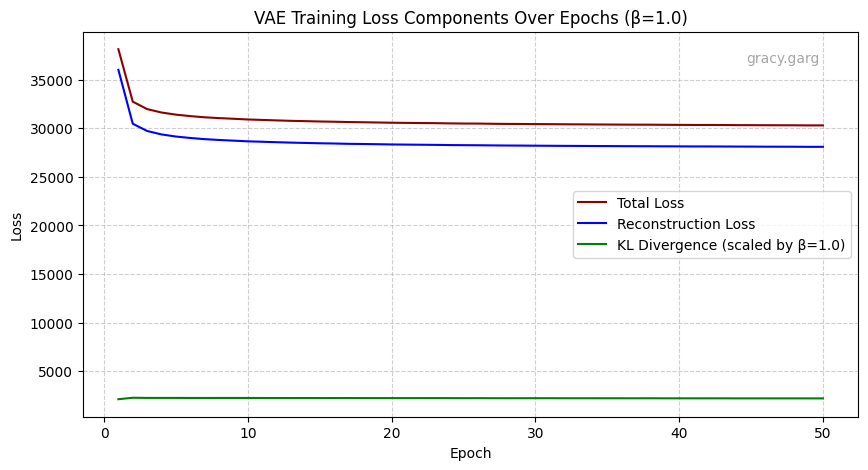

In [20]:
plot_loss_components(standard_history, BETA)

--- Starting Efficient Beta-VAE Experiments (Latent Dim=2) ---

[EXPERIMENT] Training VAE with β = 0.1
Note: Using LATENT_DIM=2 for visualization purposes
No checkpoint found. Training from scratch...
VAE initialized with Latent Dim: 2 on cuda


Epoch 10/15 (β=0.1): 100%|██████████| 469/469 [00:03<00:00, 119.95it/s, Total Loss=276.8332, Recon Loss=275.8523]


✓ Model saved to ./checkpoints/vae_beta0.1_epoch10_latent2.pt


Epoch 15/15 (β=0.1): 100%|██████████| 469/469 [00:03<00:00, 127.23it/s, Total Loss=252.0206, Recon Loss=250.9735]


✓ Model saved to ./checkpoints/vae_beta0.1_epoch15_latent2.pt

Training complete for β=0.1. Final Avg Loss: 32849.7387
✓ Model saved to ./checkpoints/vae_beta0.1_final_latent2.pt


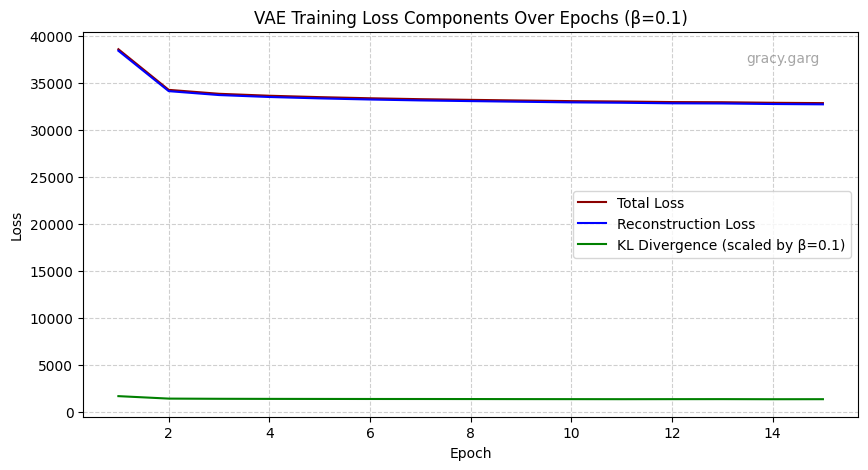


Snapshot check:
  Number of snapshots: 90
  First snapshot shape: (1500, 2)
  Labels shape: (1500,)
  Images count: 1500
✓ Saved animation to ./output/latent_evolution_beta_0.1.gif
--- Efficient Beta-VAE Experiments Complete ---


{0.1: {'total_loss': [38588.91474546908,
   34261.893077858476,
   33843.310380297175,
   33635.38138825959,
   33486.66252998401,
   33366.77450776253,
   33269.18580507063,
   33196.85011327292,
   33127.41777302106,
   33061.67987073561,
   33020.192601445895,
   32960.66861840352,
   32943.71911647121,
   32884.71577658582,
   32849.73869353012],
  'recon_loss': [38424.70966317964,
   34123.865838219615,
   33707.364622201494,
   33500.41414162447,
   33352.3108300573,
   33232.91431236674,
   33135.50381046775,
   33063.59337936434,
   32994.742524820096,
   32929.371031283314,
   32888.389808768654,
   32828.48619069829,
   32811.2771063766,
   32753.328549773454,
   32717.995431603144],
  'kl_div': [1642.0505555389025,
   1380.272834956773,
   1359.4573932964918,
   1349.6731242035498,
   1343.5170919259729,
   1338.6010369990172,
   1336.820138894673,
   1332.5665197311434,
   1326.75212881255,
   1323.0881043131164,
   1318.0278648262592,
   1321.8238046479378,
   1324.4208911

In [21]:
run_beta_experiments(train_loader=train_loader, beta_value=0.1, train_data=train_data, epochs=15) 

--- Starting Efficient Beta-VAE Experiments (Latent Dim=2) ---

[EXPERIMENT] Training VAE with β = 0.5
Note: Using LATENT_DIM=2 for visualization purposes
No checkpoint found. Training from scratch...
VAE initialized with Latent Dim: 2 on cuda


Epoch 10/15 (β=0.5): 100%|██████████| 469/469 [00:03<00:00, 124.87it/s, Total Loss=261.9050, Recon Loss=258.1978]


✓ Model saved to ./checkpoints/vae_beta0.5_epoch10_latent2.pt


Epoch 15/15 (β=0.5): 100%|██████████| 469/469 [00:03<00:00, 125.06it/s, Total Loss=251.4021, Recon Loss=247.7142]


✓ Model saved to ./checkpoints/vae_beta0.5_epoch15_latent2.pt

Training complete for β=0.5. Final Avg Loss: 33220.8770
✓ Model saved to ./checkpoints/vae_beta0.5_final_latent2.pt


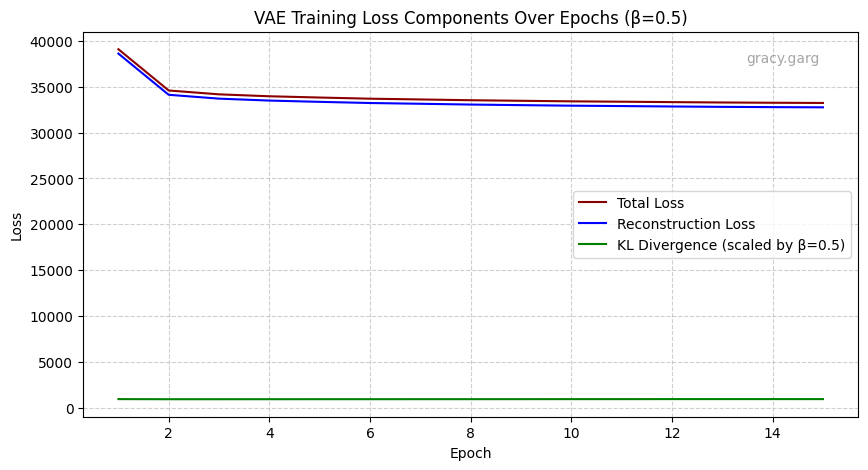


Snapshot check:
  Number of snapshots: 90
  First snapshot shape: (1500, 2)
  Labels shape: (1500,)
  Images count: 1500
✓ Saved animation to ./output/latent_evolution_beta_0.5.gif
--- Efficient Beta-VAE Experiments Complete ---


{0.5: {'total_loss': [39076.21344866072,
   34580.068201126065,
   34159.94373001066,
   33950.504006196694,
   33812.32680487073,
   33685.77614438966,
   33603.77442447362,
   33518.978065864874,
   33456.89223247601,
   33397.75474330357,
   33357.06391174707,
   33312.06658532116,
   33272.04816597814,
   33243.309076825695,
   33220.87703641391],
  'recon_loss': [38600.82366904318,
   34110.939390658314,
   33690.491746068765,
   33480.429304371,
   33341.524245402456,
   33214.899187100214,
   33131.985262026916,
   33046.81565248534,
   32983.50841218017,
   32923.314998667374,
   32882.69196845016,
   32835.871535181235,
   32795.764325692966,
   32767.417410714286,
   32745.404384328358],
  'kl_div': [950.7796549321746,
   938.2575746060435,
   938.9038441216768,
   940.149521166836,
   941.605228123126,
   941.7539516684851,
   943.5784699982926,
   944.3247627307103,
   946.7676373382113,
   948.879552519906,
   948.7438366204691,
   952.3901256569413,
   952.5678422029084,


In [22]:
run_beta_experiments(train_loader=train_loader, beta_value=0.5, train_data=train_data, epochs=15)

--- Starting Efficient Beta-VAE Experiments (Latent Dim=2) ---

[EXPERIMENT] Training VAE with β = 1.0
Note: Using LATENT_DIM=2 for visualization purposes
No checkpoint found. Training from scratch...
VAE initialized with Latent Dim: 2 on cuda


Epoch 10/15 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 120.36it/s, Total Loss=264.1491, Recon Loss=257.9856]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch10_latent2.pt


Epoch 15/15 (β=1.0): 100%|██████████| 469/469 [00:03<00:00, 123.77it/s, Total Loss=279.3545, Recon Loss=273.3136]


✓ Model saved to ./checkpoints/vae_beta1.0_epoch15_latent2.pt

Training complete for β=1.0. Final Avg Loss: 33549.9764
✓ Model saved to ./checkpoints/vae_beta1.0_final_latent2.pt


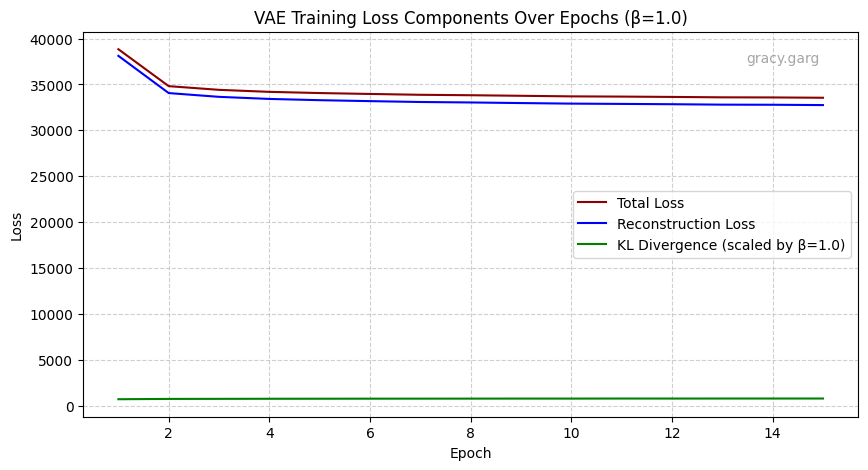


Snapshot check:
  Number of snapshots: 90
  First snapshot shape: (1500, 2)
  Labels shape: (1500,)
  Images count: 1500
✓ Saved animation to ./output/latent_evolution_beta_1.0.gif
--- Efficient Beta-VAE Experiments Complete ---


{1.0: {'total_loss': [38834.15926089419,
   34813.335487739874,
   34410.510207056235,
   34192.174973347544,
   34061.1724955024,
   33963.151698260925,
   33871.84485357809,
   33824.36639625533,
   33762.95252531983,
   33700.152356243336,
   33675.672907782515,
   33639.76974363673,
   33595.41038113007,
   33584.02949260394,
   33549.97639175773],
  'recon_loss': [38112.183102345414,
   34058.378464818765,
   33647.93586337287,
   33420.59269223081,
   33285.195737273454,
   33181.505588686035,
   33087.61874916711,
   33036.75313582756,
   32971.336799540244,
   32910.572382229475,
   32878.944133961886,
   32845.74807602612,
   32798.169796941635,
   32786.658036547175,
   32751.473726512526],
  'kl_div': [721.976125506005,
   754.9570126401336,
   762.5743577383729,
   771.5822773427088,
   775.9767884211753,
   781.6461880486657,
   784.2261102672325,
   787.6132700580524,
   791.6157947532149,
   789.579977918027,
   796.7288181980027,
   794.0216193290662,
   797.24069610790

In [23]:
run_beta_experiments(train_loader=train_loader, beta_value=1.0, train_data=train_data, epochs=15)

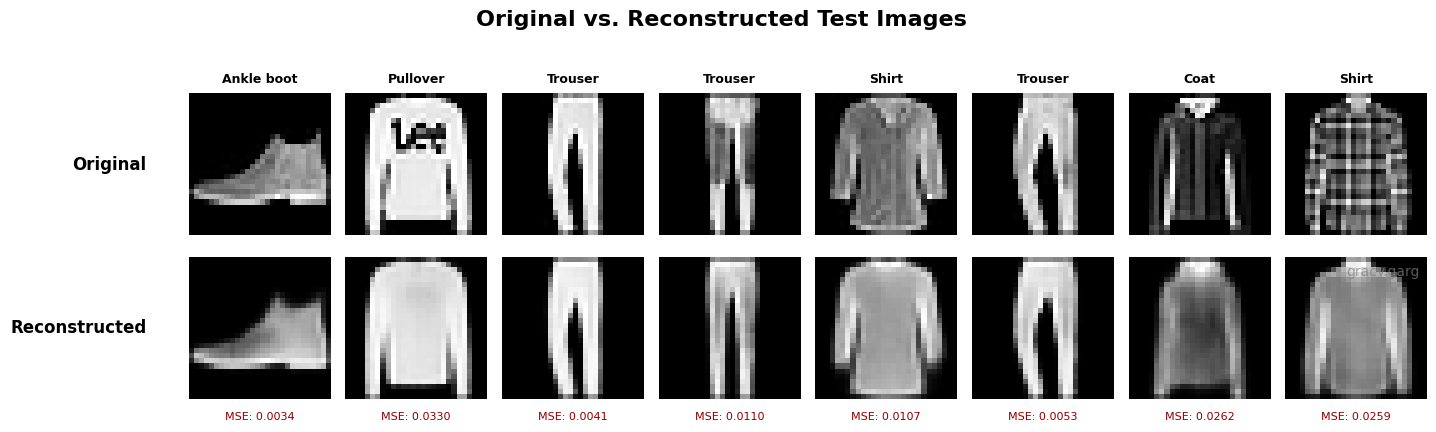

In [24]:
display_reconstructions(vae_model, test_loader, device, num_images=8)

In [27]:
real_images_batch, _ = next(iter(test_loader))
real_images = real_images_batch[:1000]  # Match the number of generated samples

sample_images=generate_new_samples(vae_model, device, num_samples=10000, plot=False) 

In [28]:
real_images_np = real_images.cpu().numpy()
sample_images_np = sample_images.cpu().numpy() if isinstance(sample_images, torch.Tensor) else sample_images
fid_val = calculate_fid_from_arrays(real_images_np, sample_images_np, device='cuda', batch_size=32, min_samples=1000)
# fid_val = calculate_fid_from_arrays(real_images_np, sample_images_np, device='cuda', batch_size=32, min_samples=1000)
print(f"FID Score: {fid_val:.4f}")               

.venv/lib64/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
.venv/lib64/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Inception_V3_Weights.IMAGENET1K_V1`. You can also use `weights=Inception_V3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_895681/3676641666.py:121: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


FID Score: 118.5641



[FROZEN LATENT EXPERIMENT] Generating samples with μ fixed to 0...
Row 1: σ= 0.1 | Sample diversity (std): 0.1752
Row 2: σ= 0.5 | Sample diversity (std): 0.2235
Row 3: σ= 1.0 | Sample diversity (std): 0.3080
✓ Higher σ → More diverse samples (larger exploration in latent space)
✓ Lower σ → More similar samples (smaller exploration around μ=0)


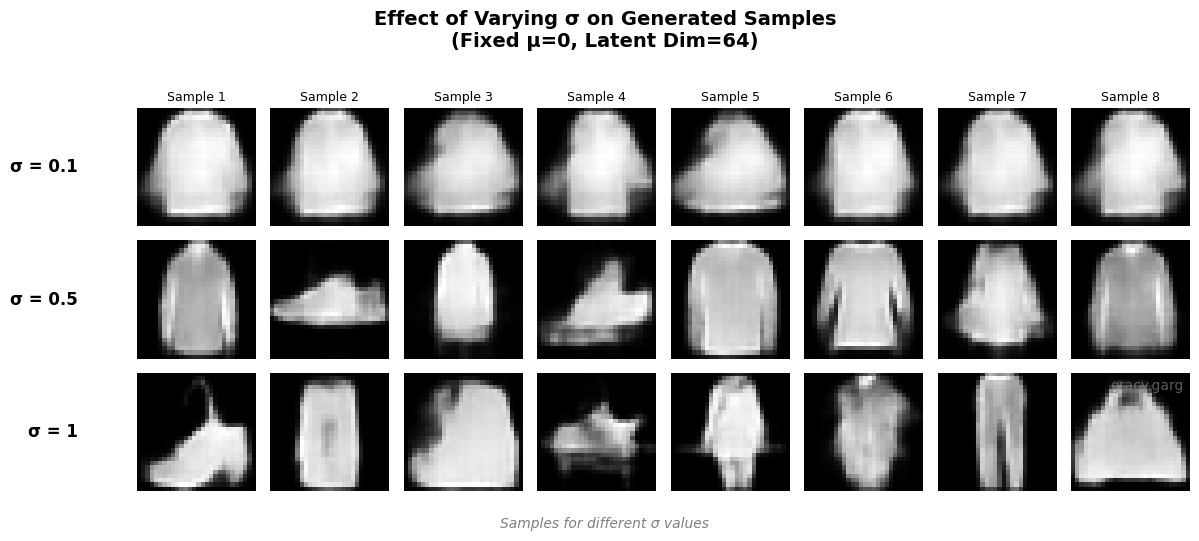

In [29]:
# 4.8 Effect of Frozen Latent Parameters
generate_frozen_samples(vae_model, device, mu_fixed=0, sigma_list=[0.1, 0.5, 1], latent_dim=LATENT_DIM)

### 2. Effect of Freezing μ and Varying σ (Sampling: z = μ + ε·σ)

Figure 2 varies σ while holding μ = 0 fixed for each sample row.

#### σ = 0.1 → Very Low Variance

* Samples look almost identical across columns.
* Clothing structures are present but extremely smooth.
* Noise is minimal → decoder receives latent vectors clustered close to 0.

#### σ = 0.5 → Moderate Variance (Good Region)

* Images become more distinct in overall shape.
* Sharpness improves slightly; features are clearer.
* Still retains good structural consistency.

#### σ = 1 → High Variance

* Outputs are more diverse, but:

  * Some images become distorted
  * Clothing shapes break down (latent vectors move too far from learned manifold)
  * Artifacts and deformed silhouettes appear

#### Summary Table of Effects

| σ value | Diversity  | Sharpness | Realism        | Interpretation                       |
| ------- | ---------- | --------- | -------------- | ------------------------------------ |
| 0.1 | ❌ low      | ❌ blurry  | ✔ realistic    | Mode collapse-like behaviour         |
| 0.5 | ✔ moderate | ✔ stable  | ✔ best         | Ideal latent sampling                |
| 1.0 | ✔ high     | ❌ noisy   | ❌ inconsistent | Decoder pushed outside learned space |

### 3. Original vs Reconstructed Images

Figure 3 compares test images to their reconstructions.

#### Observations

* Reconstructions capture:

  * global silhouette
  * class identity
  * broad textures
* But lose:

  * fine patterns (e.g., shirt plaid disappears)
  * edges become blurry
  * contrast is reduced

This aligns with the reconstruction MSE scores shown below each image (0.005–0.03).

#### Interpretation

* The VAE learns *coarse structure* well.
* High-frequency details are smoothed due to:

  * Gaussian decoder
  * KL regularization pushing latent codes toward the prior
  * limited latent dimension (20)

### Final Combined Interpretation

#### Quality

* Generated samples are recognizable and capture class-level structure.

#### Diversity

* Sampling with σ ∈ [0.3, 0.7] yields good diversity without severe distortions.

#### Realism

* Limited by the VAE's inherent blurriness.
* Larger σ reduces realism drastically.

#### Effect of Freezing μ / σ

* Fixing μ collapses diversity drastically.
* Increasing σ increases diversity at the cost of realism.